In [2]:
print("Welcome to my Insurance cliaim fraud detection project..")

Welcome to my Insurance cliaim fraud detection project..


In [3]:
import pandas as pd
df=pd.read_csv("/Users/visheshchaubey/Desktop/AI_Course/Month3-MachineLearning/insurance-claim-fraud-detection/data/carclaims.csv")
df.head(1)
# FraudFound is target
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Month                 15420 non-null  str  
 1   WeekOfMonth           15420 non-null  int64
 2   DayOfWeek             15420 non-null  str  
 3   Make                  15420 non-null  str  
 4   AccidentArea          15420 non-null  str  
 5   DayOfWeekClaimed      15420 non-null  str  
 6   MonthClaimed          15420 non-null  str  
 7   WeekOfMonthClaimed    15420 non-null  int64
 8   Sex                   15420 non-null  str  
 9   MaritalStatus         15420 non-null  str  
 10  Age                   15420 non-null  int64
 11  Fault                 15420 non-null  str  
 12  PolicyType            15420 non-null  str  
 13  VehicleCategory       15420 non-null  str  
 14  VehiclePrice          15420 non-null  str  
 15  PolicyNumber          15420 non-null  int64
 16  RepNumber      

In [4]:
df.shape
df.columns.to_list

<bound method IndexOpsMixin.tolist of Index(['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea',
       'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex',
       'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory',
       'VehiclePrice', 'PolicyNumber', 'RepNumber', 'Deductible',
       'DriverRating', 'Days:Policy-Accident', 'Days:Policy-Claim',
       'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder',
       'PoliceReportFiled', 'WitnessPresent', 'AgentType',
       'NumberOfSuppliments', 'AddressChange-Claim', 'NumberOfCars', 'Year',
       'BasePolicy', 'FraudFound'],
      dtype='str')>

In [5]:
print(df.isnull().sum().sort_values(ascending=False))

Month                   0
Deductible              0
BasePolicy              0
Year                    0
NumberOfCars            0
AddressChange-Claim     0
NumberOfSuppliments     0
AgentType               0
WitnessPresent          0
PoliceReportFiled       0
AgeOfPolicyHolder       0
AgeOfVehicle            0
PastNumberOfClaims      0
Days:Policy-Claim       0
Days:Policy-Accident    0
DriverRating            0
RepNumber               0
WeekOfMonth             0
PolicyNumber            0
VehiclePrice            0
VehicleCategory         0
PolicyType              0
Fault                   0
Age                     0
MaritalStatus           0
Sex                     0
WeekOfMonthClaimed      0
MonthClaimed            0
DayOfWeekClaimed        0
AccidentArea            0
Make                    0
DayOfWeek               0
FraudFound              0
dtype: int64


In [6]:
# count  duplicates
df.duplicated().sum()


np.int64(0)

Understand the target variable

In [7]:
print(df["FraudFound"].value_counts()
)# we can conclude these have class imbalance problem ..
df["FraudFound"].value_counts(normalize=True).mul(100).round(2)

FraudFound
No     14497
Yes      923
Name: count, dtype: int64


FraudFound
No     94.01
Yes     5.99
Name: proportion, dtype: float64

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [9]:
df.shape
df.columns.tolist()
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Month                 15420 non-null  str  
 1   WeekOfMonth           15420 non-null  int64
 2   DayOfWeek             15420 non-null  str  
 3   Make                  15420 non-null  str  
 4   AccidentArea          15420 non-null  str  
 5   DayOfWeekClaimed      15420 non-null  str  
 6   MonthClaimed          15420 non-null  str  
 7   WeekOfMonthClaimed    15420 non-null  int64
 8   Sex                   15420 non-null  str  
 9   MaritalStatus         15420 non-null  str  
 10  Age                   15420 non-null  int64
 11  Fault                 15420 non-null  str  
 12  PolicyType            15420 non-null  str  
 13  VehicleCategory       15420 non-null  str  
 14  VehiclePrice          15420 non-null  str  
 15  PolicyNumber          15420 non-null  int64
 16  RepNumber      

,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange-Claim,NumberOfCars,Year,BasePolicy,FraudFound
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability,No
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision,No
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision,No
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability,No
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision,No


EDA Steps---

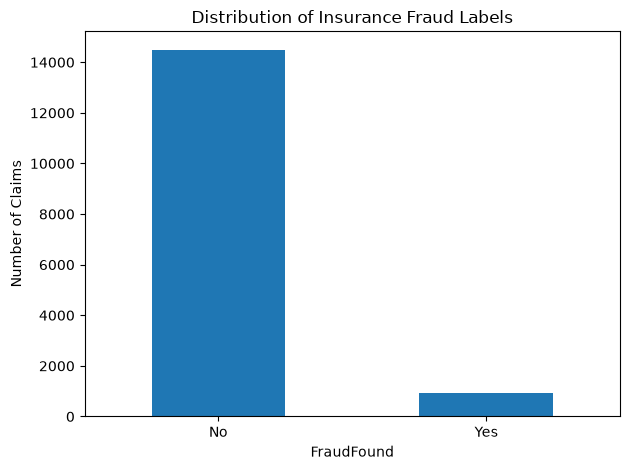

In [10]:
import matplotlib.pyplot as plt

df["FraudFound"].value_counts().plot(
    kind="bar",
    rot=0
)

plt.title("Distribution of Insurance Fraud Labels")
plt.xlabel("FraudFound")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()

In [11]:
# understand the feature..
print(df.columns.tolist())

['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'PolicyNumber', 'RepNumber', 'Deductible', 'DriverRating', 'Days:Policy-Accident', 'Days:Policy-Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange-Claim', 'NumberOfCars', 'Year', 'BasePolicy', 'FraudFound']


In [12]:
# summarize numerical columns
df.describe()

,WeekOfMonth,WeekOfMonthClaimed,Age,PolicyNumber,RepNumber,Deductible,DriverRating,Year
count,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000
mean,2.788586,2.693969,39.855707,7710.500000,8.483268,407.704280,2.487808,1994.866472
std,1.287585,1.259115,13.492377,4451.514911,4.599948,43.950998,1.119453,0.803313
min,1.000000,1.000000,0.000000,1.000000,1.000000,300.000000,1.000000,1994.000000
25%,2.000000,2.000000,31.000000,3855.750000,5.000000,400.000000,1.000000,1994.000000
50%,3.000000,3.000000,38.000000,7710.500000,8.000000,400.000000,2.000000,1995.000000
75%,4.000000,4.000000,48.000000,11565.250000,12.000000,400.000000,3.000000,1996.000000
max,5.000000,5.000000,80.000000,15420.000000,16.000000,700.000000,4.000000,1996.000000


In [13]:
# summarize categorical column
df.describe(include="object")

/var/folders/bw/1xvd_9fx56z0lnplnf7p6nlr0000gn/T/ipykernel_9268/627516547.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Month,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,Sex,MaritalStatus,Fault,PolicyType,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange-Claim,NumberOfCars,BasePolicy,FraudFound
count,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,...,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420
unique,12,7,19,2,8,13,2,4,2,9,...,8,9,2,2,2,4,5,5,3,2
top,Jan,Monday,Pontiac,Urban,Monday,Jan,Male,Married,Policy Holder,Sedan - Collision,...,7 years,31 to 35,No,No,External,none,no change,1 vehicle,Collision,No
freq,1411,2616,3837,13822,3757,1446,13000,10625,11230,5584,...,5807,5593,14992,15333,15179,7047,14324,14316,5962,14497


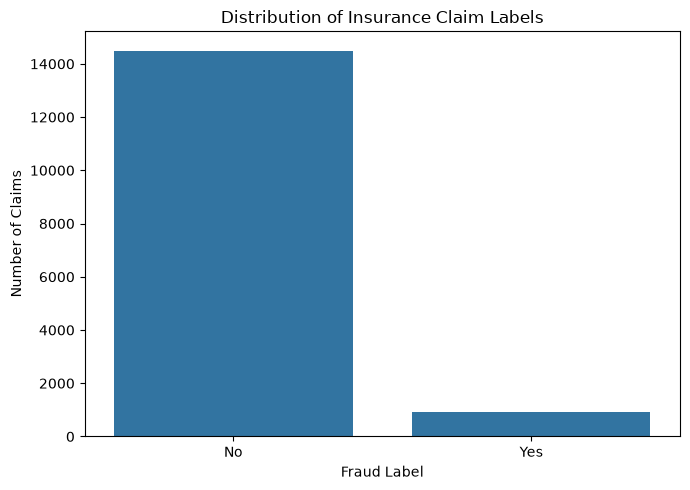

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fraud_counts = df["FraudFound"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(x=fraud_counts.index, y=fraud_counts.values)

plt.title("Distribution of Insurance Claim Labels")
plt.xlabel("Fraud Label")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()


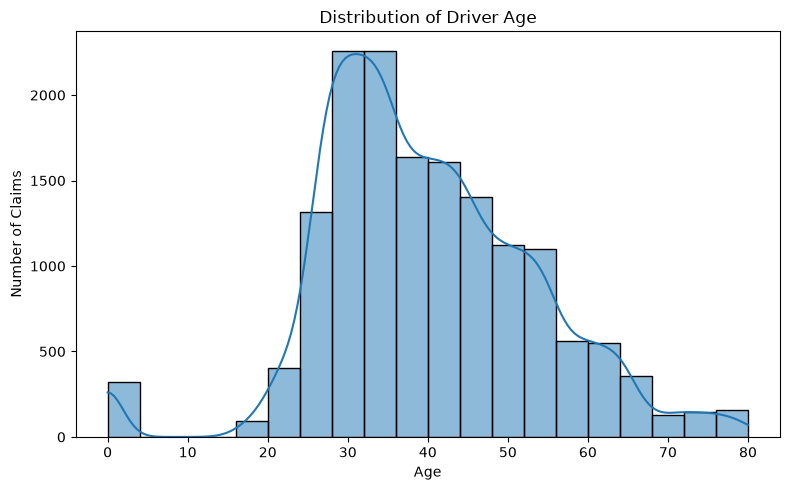

In [15]:
# A distribution shows how frequently different values occur. -- so we use histogram here
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="Age",
    bins=20,
    kde=True
)
plt.title("Distribution of Driver Age")
plt.xlabel("Age")
plt.ylabel("Number of Claims")

plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

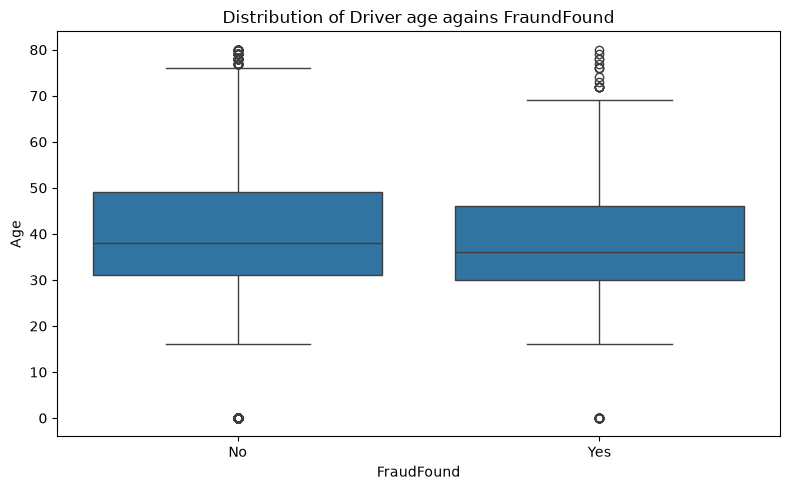

In [16]:
# comparing this with the target  use boxplot for this
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="FraudFound",
    y="Age"
)
plt.title("Distribution of Driver age agains FraundFound")
plt.xlabel("FraudFound")
plt.ylabel("Age")
plt.tight_layout()
plt.show

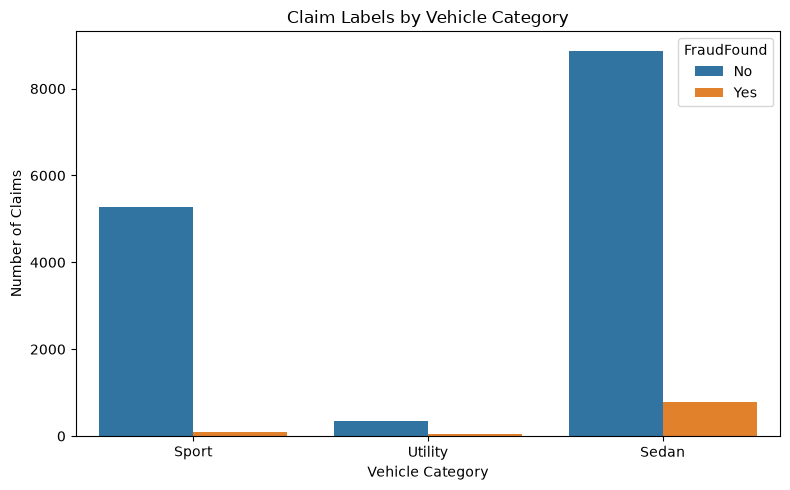

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="VehicleCategory",
    hue="FraudFound"
)

plt.title("Claim Labels by Vehicle Category")
plt.xlabel("Vehicle Category")
plt.ylabel("Number of Claims")

plt.tight_layout()
plt.show()

In [18]:
fraud_rate_by_vehicle = (
    df.groupby("VehicleCategory")["FraudFound"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .sort_values(ascending=False)
)
# fraud_rate_by_year=(
#     df.groupby("Year")["FraudFound"]
#     .apply(lambda s: (s == "Yes").mean() * 100)
#     .sort_values(ascending=False)
# )
print(fraud_rate_by_vehicle.round(2))
# print(fraud_rate_by_year.round(2))


VehicleCategory
Utility    11.25
Sedan       8.22
Sport       1.57
Name: FraudFound, dtype: float64


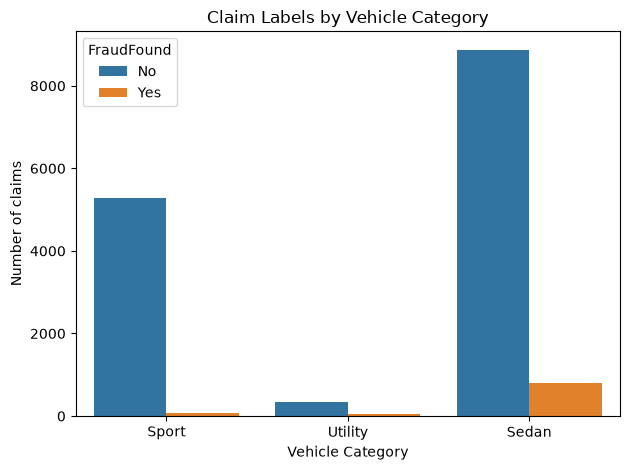

In [19]:
plt.Figure(figsize=(8,5))
sns.countplot(
    data=df,
    x="VehicleCategory",
    # y="Year",
    hue="FraudFound"
)
plt.title("Claim Labels by Vehicle Category")
plt.xlabel("Vehicle Category")
plt.ylabel("Number of claims")
plt.tight_layout()
plt.show()

In [20]:
print(df.describe)

<bound method NDFrame.describe of       Month  WeekOfMonth  DayOfWeek     Make AccidentArea DayOfWeekClaimed  \
0       Dec            5  Wednesday    Honda        Urban          Tuesday   
1       Jan            3  Wednesday    Honda        Urban           Monday   
2       Oct            5     Friday    Honda        Urban         Thursday   
3       Jun            2   Saturday   Toyota        Rural           Friday   
4       Jan            5     Monday    Honda        Urban          Tuesday   
...     ...          ...        ...      ...          ...              ...   
15415   Nov            4     Friday   Toyota        Urban          Tuesday   
15416   Nov            5   Thursday  Pontiac        Urban           Friday   
15417   Nov            5   Thursday   Toyota        Rural           Friday   
15418   Dec            1     Monday   Toyota        Urban         Thursday   
15419   Dec            2  Wednesday   Toyota        Urban         Thursday   

      MonthClaimed  WeekOfMon

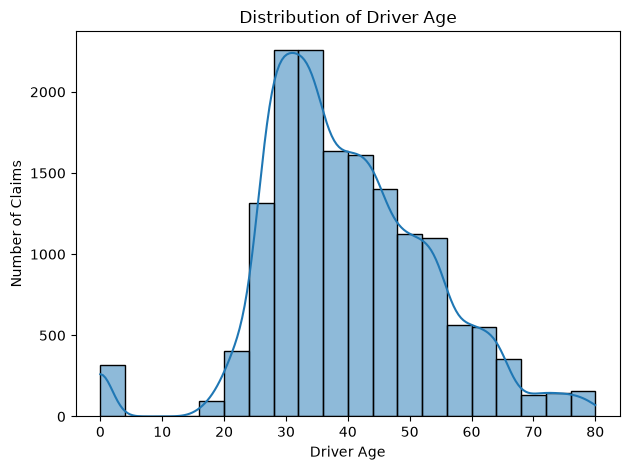

In [21]:
# plot the distribution of age 
age_value_count=df["Age"].value_counts()
age_value_count.sum()

plt.Figure(figsize=(8, 5))
# histo plot we will use to display the plot for age distribution
sns.histplot(
    data=df,
    x="Age",
    bins=20,
    kde=True
)
plt.title("Distribution of Driver Age")
plt.xlabel("Driver Age")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()


In [22]:
# Calculate the fraud rate by VehicleCategory
fraud_rate_vehicle_category=(
    df.groupby("VehicleCategory")["FraudFound"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .sort_values(ascending=False)
)
fraud_rate_vehicle_category


VehicleCategory
Utility    11.253197
Sedan       8.220453
Sport       1.567749
Name: FraudFound, dtype: float64

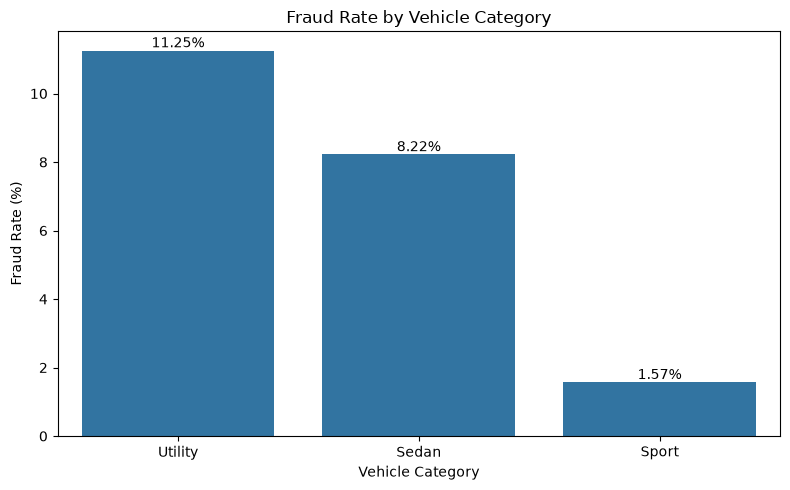

In [23]:
fraud_rate_by_vehicle = (
    df.groupby("VehicleCategory")["FraudFound"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=fraud_rate_by_vehicle.index,
    y=fraud_rate_by_vehicle.values
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Fraud Rate by Vehicle Category")
plt.xlabel("Vehicle Category")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

In [24]:
df["VehicleCategory"].value_counts()
# this will show the counts of values in the vehicle category column now if i want to get its percentage
df["VehicleCategory"].value_counts(normalize=True).mul(100).round(2)

# now i want to check the percentage of fraud as per the vehicle category
# with upto 2 places of decimal

fraud_rate=(df.groupby("VehicleCategory")["FraudFound"]
            .apply(lambda s: (s=="Yes").mean()*100).round(1)
            .sort_values(ascending=False)
)
# fraud_rate_vehicle_category=(
#     df.groupby("VehicleCategory")["FraudFound"]
#     .apply(lambda s: (s == "Yes").mean() * 100)
#     .sort_values(ascending=False)
# )
# fraud_rate_vehicle_category
print(fraud_rate)


VehicleCategory
Utility    11.3
Sedan       8.2
Sport       1.6
Name: FraudFound, dtype: float64


Next EDA task: Analyze AccidentArea

In [25]:
fraud_rate_by_area = (
    df.groupby("AccidentArea")["FraudFound"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print(fraud_rate_by_area.round(2))

AccidentArea
Rural    8.32
Urban    5.72
Name: FraudFound, dtype: float64


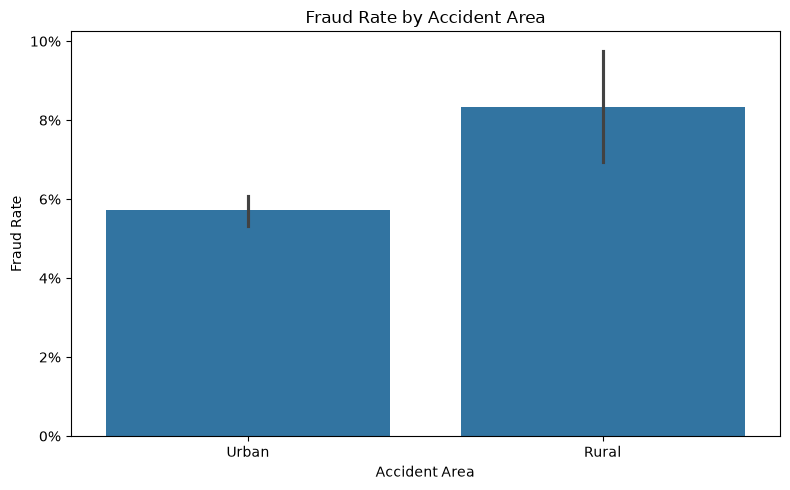

In [26]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="AccidentArea",
    y=df["FraudFound"].eq("Yes").astype(int)
)

ax.set_title("Fraud Rate by Accident Area")
ax.set_xlabel("Accident Area")
ax.set_ylabel("Fraud Rate")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

plt.tight_layout()
plt.show()

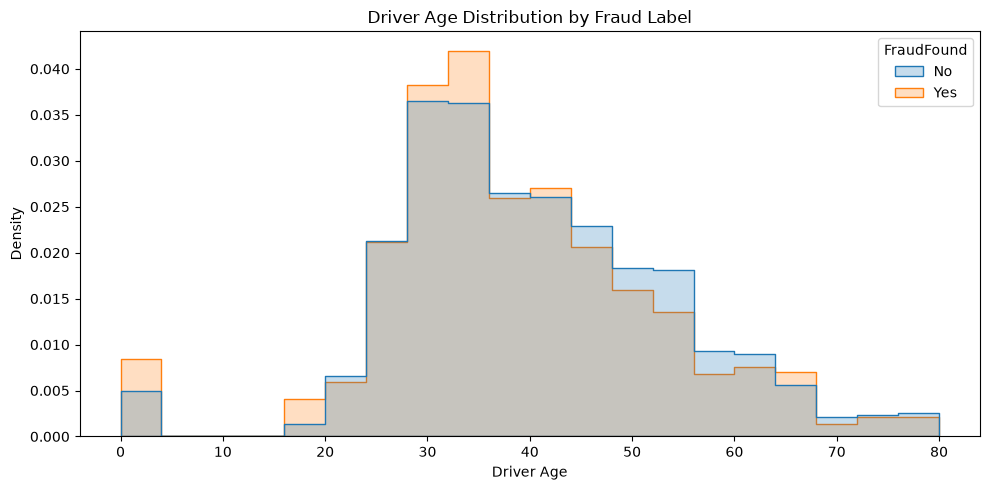

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="FraudFound",
    bins=20,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Driver Age Distribution by Fraud Label")
plt.xlabel("Driver Age")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

In [28]:
age_analysis = df.groupby("FraudFound")["Age"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(age_analysis.round(2))

,count,mean,median,std,min,max
FraudFound,,,,,,
No,14497,39.96,38.0,13.46,0,80
Yes,923,38.27,36.0,13.87,0,80


In [29]:
# Analyze Fault vs. FraudFound
fault_analysis = df.groupby("Fault").agg(
    total_claims=("FraudFound", "count"),
    fraud_claims=("FraudFound", lambda s: (s == "Yes").sum())
)

fault_analysis["fraud_rate_percent"] = (
    fault_analysis["fraud_claims"]
    / fault_analysis["total_claims"]
    * 100
)

display(fault_analysis.round(2))

,total_claims,fraud_claims,fraud_rate_percent
Fault,,,
Policy Holder,11230,886,7.89
Third Party,4190,37,0.88


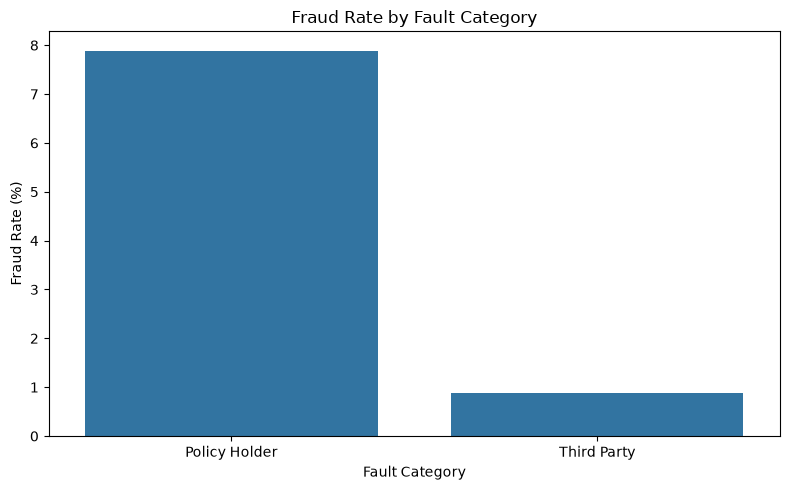

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=fault_analysis.reset_index(),
    x="Fault",
    y="fraud_rate_percent"
)

plt.title("Fraud Rate by Fault Category")
plt.xlabel("Fault Category")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

In [31]:
make_analysis = df.groupby("Make").agg(
    total_claims=("FraudFound", "count"),
    fraud_claims=("FraudFound", lambda s: (s == "Yes").sum())
)

make_analysis["fraud_rate_percent"] = (
    make_analysis["fraud_claims"]
    / make_analysis["total_claims"]
    * 100
)

make_analysis = make_analysis.sort_values(
    "fraud_rate_percent",
    ascending=False
)

display(make_analysis.round(2))

,total_claims,fraud_claims,fraud_rate_percent
Make,,,
Mecedes,4,1,25.00
Accura,472,59,12.50
Saturn,58,6,10.34
Saab,108,11,10.19
Ford,450,33,7.33
Mercury,83,6,7.23
BMW,15,1,6.67
Honda,2801,179,6.39
Toyota,3121,186,5.96


In [32]:
price_analysis = df.groupby("VehiclePrice").agg(
    total_claims=("FraudFound", "count"),
    fraud_claims=("FraudFound", lambda s: (s == "Yes").sum())
)

price_analysis["fraud_rate_percent"] = (
    price_analysis["fraud_claims"]
    / price_analysis["total_claims"]
    * 100
)

display(price_analysis.sort_values(
    "fraud_rate_percent",
    ascending=False
).round(2))

,total_claims,fraud_claims,fraud_rate_percent
VehiclePrice,,,
"less than 20,000",1096,103,9.40
"more than 69,000",2164,189,8.73
"40,000 to 59,000",461,31,6.72
"20,000 to 29,000",8079,421,5.21
"30,000 to 39,000",3533,175,4.95
"60,000 to 69,000",87,4,4.60


In [33]:
print(df.columns.tolist())

['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'PolicyNumber', 'RepNumber', 'Deductible', 'DriverRating', 'Days:Policy-Accident', 'Days:Policy-Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange-Claim', 'NumberOfCars', 'Year', 'BasePolicy', 'FraudFound']


In [34]:
df[
    [
        "Fault",
        "Days:Policy-Accident",
        "Days:Policy-Claim",
        "PastNumberOfClaims",
        "NumberOfSuppliments",
        "FraudFound"
    ]
].tail(10)

,Fault,Days:Policy-Accident,Days:Policy-Claim,PastNumberOfClaims,NumberOfSuppliments,FraudFound
15410,Third Party,more than 30,more than 30,2 to 4,more than 5,No
15411,Third Party,more than 30,more than 30,1,none,No
15412,Policy Holder,more than 30,more than 30,more than 4,more than 5,Yes
15413,Policy Holder,more than 30,more than 30,1,1 to 2,No
15414,Third Party,more than 30,more than 30,none,1 to 2,No
15415,Policy Holder,more than 30,more than 30,2 to 4,none,Yes
15416,Policy Holder,more than 30,more than 30,more than 4,more than 5,No
15417,Policy Holder,more than 30,more than 30,more than 4,1 to 2,Yes
15418,Third Party,more than 30,more than 30,none,more than 5,No
15419,Policy Holder,more than 30,more than 30,none,1 to 2,Yes


In [35]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


EDA- Summary


In [36]:
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["FraudFound"].value_counts())

print("\nTarget percentages:")
print(
    df["FraudFound"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nMissing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nVehicle category fraud rates:")
print(
    (
        df.groupby("VehicleCategory")["FraudFound"]
        .apply(lambda s: (s == "Yes").mean() * 100)
    ).round(2)
)

Dataset shape: (15420, 33)

Target distribution:
FraudFound
No     14497
Yes      923
Name: count, dtype: int64

Target percentages:
FraudFound
No     94.01
Yes     5.99
Name: proportion, dtype: float64

Missing values: 0

Duplicate rows: 0

Vehicle category fraud rates:
VehicleCategory
Sedan       8.22
Sport       1.57
Utility    11.25
Name: FraudFound, dtype: float64


In [37]:
# 1. Review our EDA findings
# Your actual results are:
# Check	            Result	    Interpretation
# Total records	    15,420	    15,420 insurance claim records
# Total columns	     33	        32 potential input features and 1 target column
# Claims labeled    No,14,497	Majority class
# Claims labeled    Yes,923     Minority class
# Fraud-label %	    5.99%	    Imbalanced target
# Missing values	0	No null values detected
# Duplicate rows	0	No exact duplicate rows detected

In [38]:
feature_summary = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "unique_values": [
        df[column].nunique()
        for column in df.columns
    ]
})

display(feature_summary)

,column,dtype,unique_values
0,Month,str,12
1,WeekOfMonth,int64,5
2,DayOfWeek,str,7
3,Make,str,19
4,AccidentArea,str,2
5,DayOfWeekClaimed,str,8
6,MonthClaimed,str,13
7,WeekOfMonthClaimed,int64,5
8,Sex,str,2
9,MaritalStatus,str,4


In [39]:
# For now, we'll exclude:
# - FraudFound from the input features because it is our target.
# - PolicyNumber because it appears to be an identifier.
# - Fault because we have not yet established whether it is available at the intended prediction time.
# - RepNumber because it may encode representative-specific patterns that need separate investigation.


In [40]:
# Target variable
y = df["FraudFound"]

# Features Variables
columns_to_drop=["FraudFound","PolicyNumber","Fault","RepNumber"]
X=df.drop(columns=columns_to_drop)
print(f"Feature variables shape: {X.shape}")

print(f"Target Variable shape: {y.shape}")

Feature variables shape: (15420, 29)
Target Variable shape: (15420,)


Train/Test Split

In [41]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training features: (12336, 29)
Testing features: (3084, 29)

Training target distribution:
FraudFound
No     94.02
Yes     5.98
Name: proportion, dtype: float64

Testing target distribution:
FraudFound
No     94.0
Yes     6.0
Name: proportion, dtype: float64


Identifying Numerical and Categorical columns...

In [42]:
# Identify numerical columns
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()

# Identify categorical columns
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Numerical features:")
print(numeric_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:")
print(categorical_features)

Number of numerical features: 6
Numerical features:
['WeekOfMonth', 'WeekOfMonthClaimed', 'Age', 'Deductible', 'DriverRating', 'Year']

Number of categorical features: 23
Categorical features:
['Month', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'Sex', 'MaritalStatus', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Days:Policy-Accident', 'Days:Policy-Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange-Claim', 'NumberOfCars', 'BasePolicy']


step-Creating preprocessing pipeline

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# Preprocessing for categorical and numerical columns
# categorical_features , numeric_features
numerical_transformer=Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)
categorical_transformer=Pipeline(
    steps=[
        ("onehot",OneHotEncoder(handle_unknown="ignore"))
    ]
)
# combining these preprocessing branches in pipeline
preprocessor=ColumnTransformer(
    transformers=[
        # ("num","passthrough",numeric_features),
        ("num",numerical_transformer,numeric_features),
        ("cat",categorical_transformer,categorical_features)
    ]
)
# creating the model
model=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",DecisionTreeClassifier(random_state=42))
    ]
)
print(f"Preprocessing pipeline and Decision Tree created successfully!")

Preprocessing pipeline and Decision Tree created successfully!


Train the Model

In [44]:
# After preprocessing of the column transformer we have to now train the model .fit
trained_model=model.fit(X_train, y_train)
print(f"Model Training completed successfully..")

Model Training completed successfully..


In [45]:
y_pred = model.predict(X_test)

print("Predictions completed!")

print("\nFirst 20 actual labels:")
print(y_test.head(20).tolist())

print("\nFirst 20 predicted labels:")
print(y_pred[:20].tolist())

Predictions completed!

First 20 actual labels:
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No']

First 20 predicted labels:
['No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No']


In [46]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

print("Confusion Matrix:")
print(cm)

# Evaluation Metrics
print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, pos_label="Yes", zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, pos_label="Yes", zero_division=0
))

print("F1 Score:", f1_score(
    y_test, y_pred, pos_label="Yes", zero_division=0
))

# Detailed Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[2700  199]
 [ 149   36]]

Accuracy: 0.8871595330739299
Precision: 0.15319148936170213
Recall: 0.1945945945945946
F1 Score: 0.17142857142857143

Classification Report:
              precision    recall  f1-score   support

          No       0.95      0.93      0.94      2899
         Yes       0.15      0.19      0.17       185

    accuracy                           0.89      3084
   macro avg       0.55      0.56      0.56      3084
weighted avg       0.90      0.89      0.89      3084



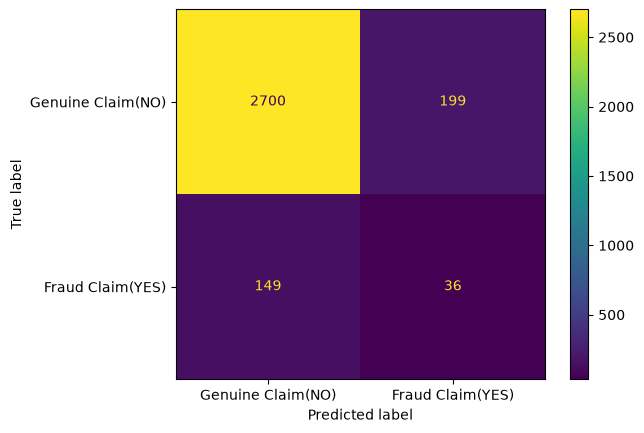

In [47]:
# No = Genuine claim
# Yes = Fraudulent claim


from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm=confusion_matrix(
    y_test,y_pred,labels=["No","Yes"]
)
cm
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine Claim(NO)", "Fraud Claim(YES)"]
)

display.plot()
plt.show()

In [48]:
dt = model.named_steps["classifier"]

print("Model:", dt)
print("Tree Depth:", dt.get_depth())
print("Number of Leaves:", dt.get_n_leaves())
print("Number of Features:", dt.n_features_in_)

Model: DecisionTreeClassifier(random_state=42)
Tree Depth: 35
Number of Leaves: 1066
Number of Features: 144


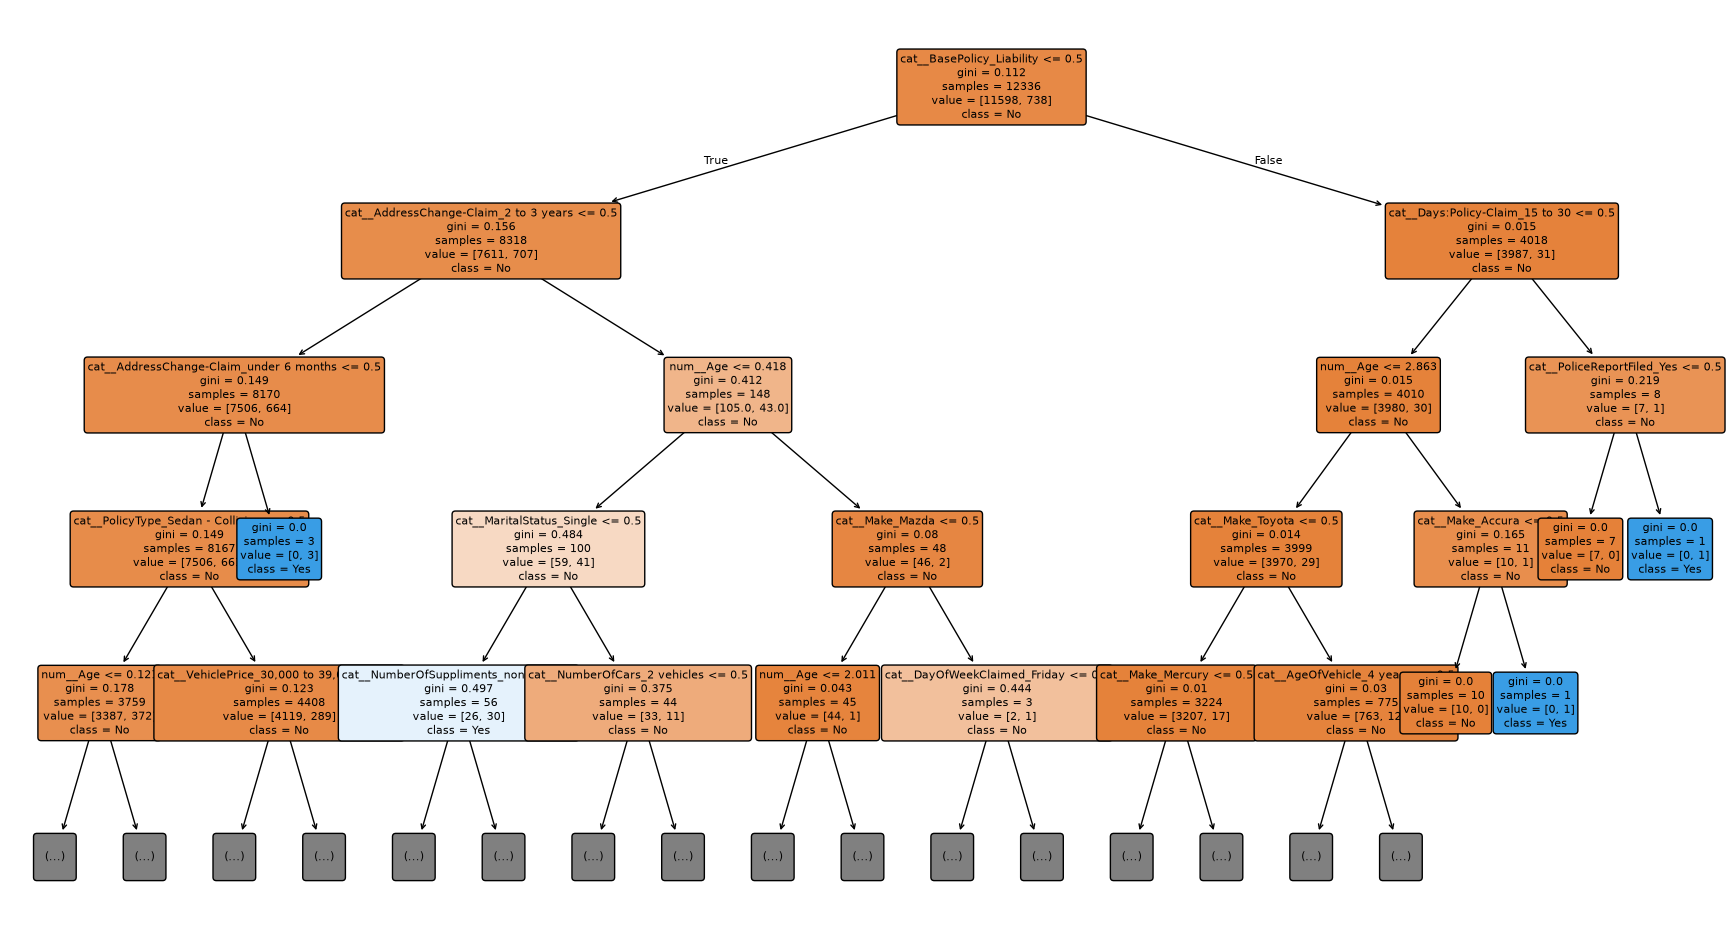

In [49]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 12))

plot_tree(
    dt,
    max_depth=4,
    feature_names=model.named_steps["preprocessor"].get_feature_names_out(),
    class_names=dt.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()